In [5]:
!pip install pandas numpy matplotlib seaborn reportlab

1. DATASET OVERVIEW
Dataset shape: (205, 26)

First five rows:
   symboling  normalized_losses         make fuel_type aspiration num_doors  \
0          3                NaN  alfa-romero       gas        std       two   
1          3                NaN  alfa-romero       gas        std       two   
2          1                NaN  alfa-romero       gas        std       two   
3          2              164.0         audi       gas        std      four   
4          2              164.0         audi       gas        std      four   

    body_style drive_wheels engine_location  wheel_base  ...  engine_size  \
0  convertible          rwd           front        88.6  ...          130   
1  convertible          rwd           front        88.6  ...          130   
2    hatchback          rwd           front        94.5  ...          152   
3        sedan          fwd           front        99.8  ...          109   
4        sedan          4wd           front        99.4  ...          136   


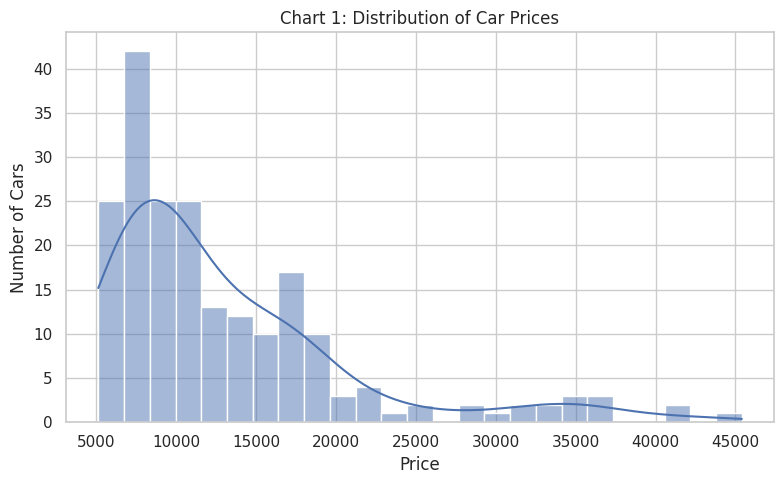

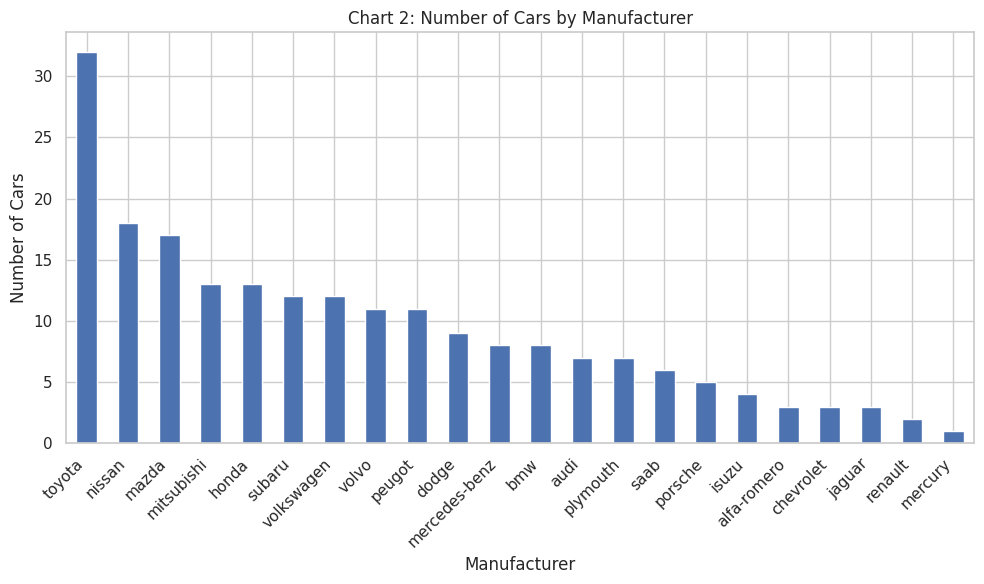

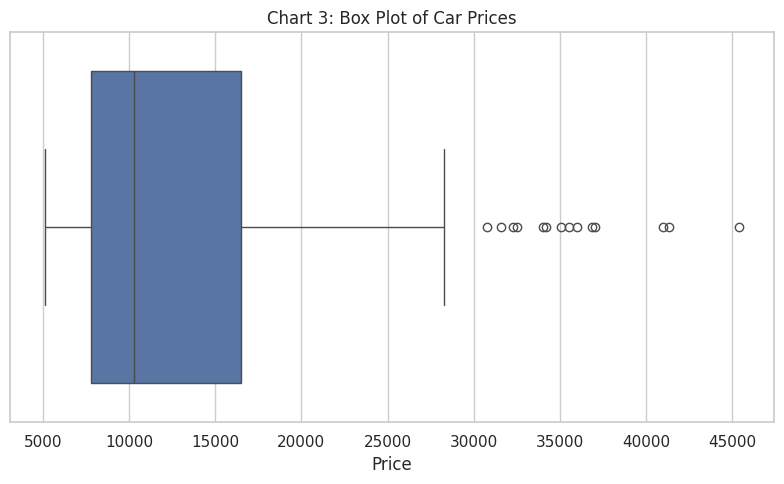

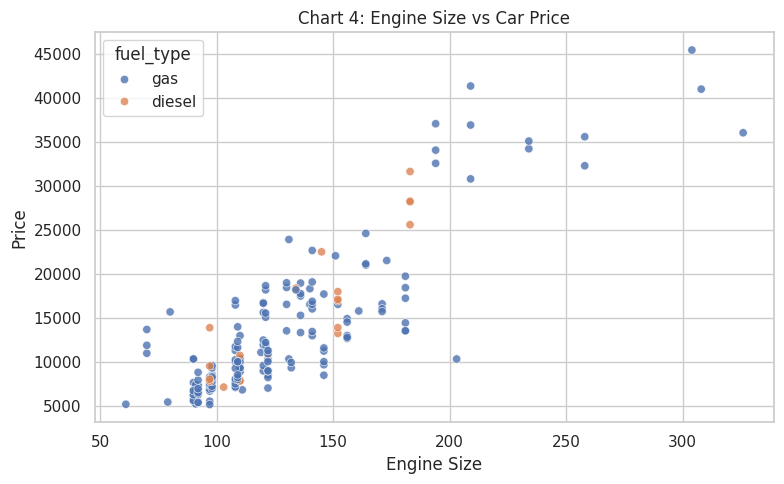

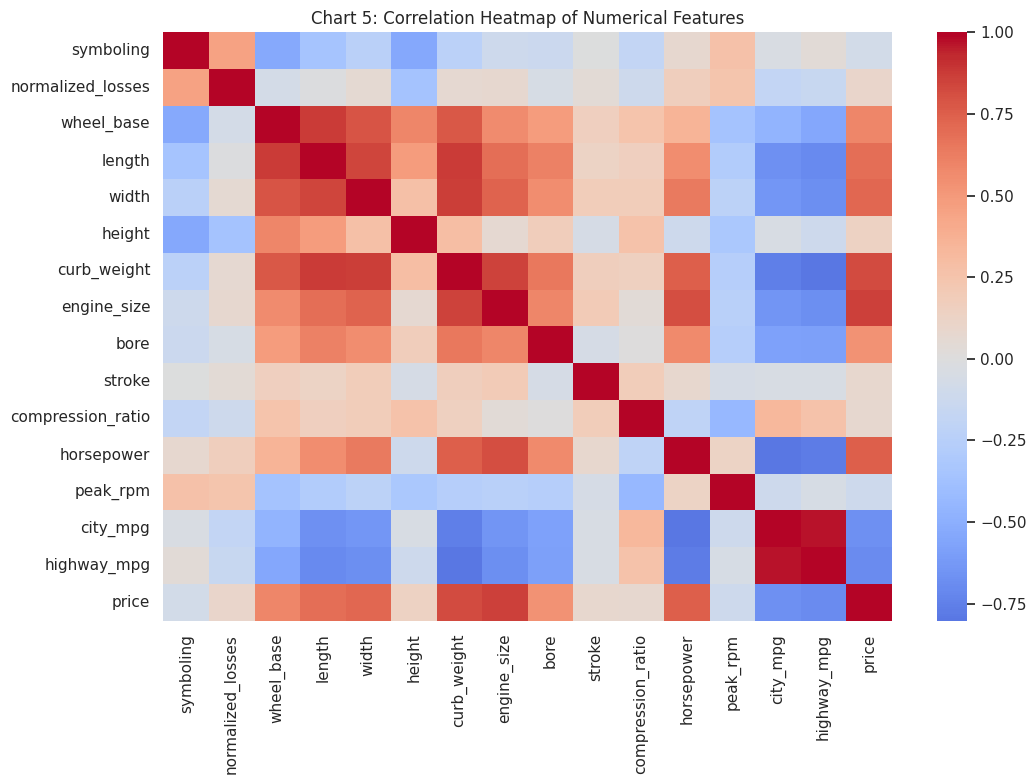

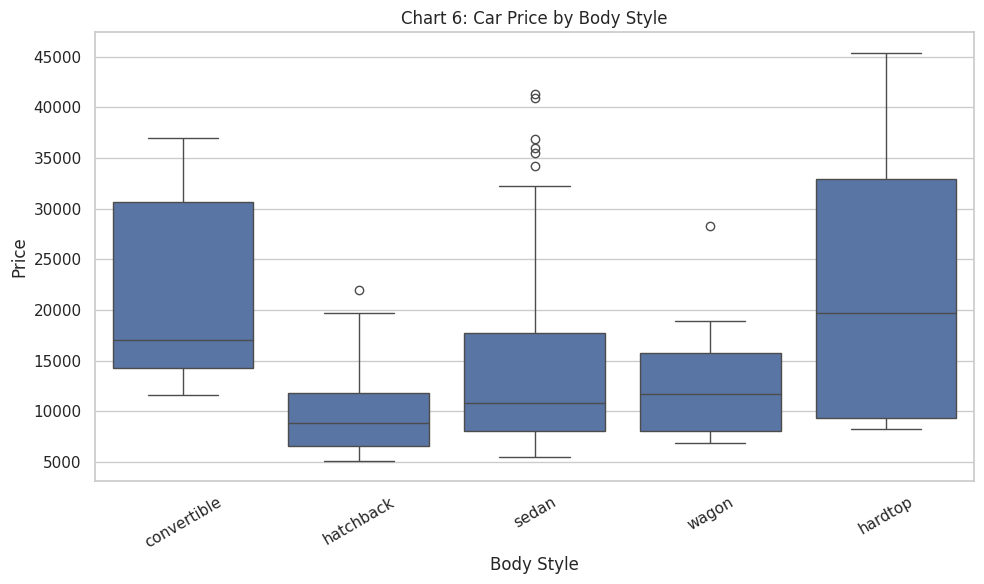

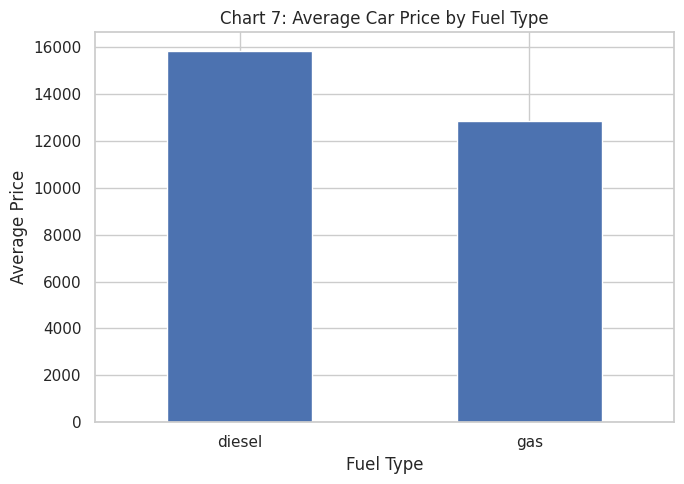

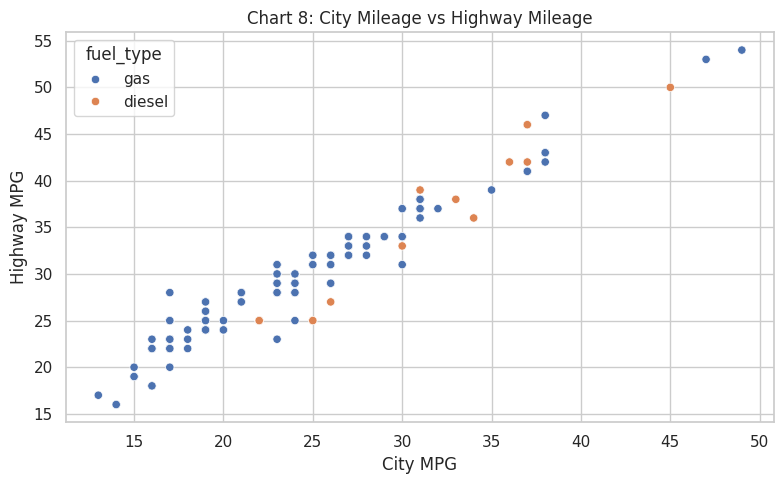


6. POTENTIAL NUMERICAL OUTLIERS
     column  lower_bound  upper_bound  potential_outlier_count
      price      -5280.0      29568.0                       14
 horsepower          1.0        185.0                        6
engine_size         31.0        207.0                       10
curb_weight        960.0       4120.0                        0

7. KEY FINDINGS FROM THE CLEANED DATA
1. Most represented manufacturer: toyota (32 cars in this dataset).
2. Highest average price by manufacturer: jaguar (average price 34600.00).
3. Correlation between engine size and price: 0.86.
4. Correlation between city and highway mileage: 0.97.
5. Most common body style: sedan (96 cars).
6. Highest average price by body style: hardtop (average price 22208.50).
7. Fuel type with the highest average city mileage: diesel (average 30.30 MPG).

EDA ANALYSIS COMPLETED
Cleaned data, statistics, findings and charts saved in:
/content/cars_eda_output

Charts created: 8


In [10]:
# ============================================================
# CARS DATASET - EXPLORATORY DATA ANALYSIS (EDA)
# Assignment: Data cleaning, statistics, charts and insights
# Dataset: UCI Automobile Dataset
# ============================================================

import os
import warnings
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# 1. CREATE OUTPUT FOLDER
OUTPUT_DIR = "cars_eda_output"
CHART_DIR = os.path.join(OUTPUT_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

# 2. LOAD DATASET
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/autos/imports-85.data"
)

columns = [
    "symboling", "normalized_losses", "make", "fuel_type",
    "aspiration", "num_doors", "body_style", "drive_wheels",
    "engine_location", "wheel_base", "length", "width",
    "height", "curb_weight", "engine_type", "num_cylinders",
    "engine_size", "fuel_system", "bore", "stroke",
    "compression_ratio", "horsepower", "peak_rpm",
    "city_mpg", "highway_mpg", "price"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

# 3. DATA QUALITY CHECKS
print("\n" + "=" * 60)
print("2. MISSING VALUES BEFORE CLEANING")
print("=" * 60)

missing_before = df.isnull().sum()
print(missing_before[missing_before > 0].sort_values(ascending=False))

print("\nTotal missing cells:", int(df.isnull().sum().sum()))
print("Duplicate rows before cleaning:", int(df.duplicated().sum()))

# Save a record of the initial data quality
missing_before.to_csv(
    os.path.join(OUTPUT_DIR, "missing_values_before.csv"),
    header=["missing_count"]
)

# 4. CLEAN DATA
df_clean = df.copy()

# Convert columns that should be numeric
numeric_columns = [
    "symboling", "normalized_losses", "wheel_base", "length",
    "width", "height", "curb_weight", "engine_size", "bore",
    "stroke", "compression_ratio", "horsepower", "peak_rpm",
    "city_mpg", "highway_mpg", "price"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Remove exact duplicate rows
duplicates_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

# Fill numeric missing values with each column's median.
# Median is less affected by extreme values than the mean.
for col in numeric_columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical missing values with the most frequent value.
categorical_columns = [
    col for col in df_clean.columns
    if col not in numeric_columns
]

for col in categorical_columns:
    if df_clean[col].isnull().any():
        mode_values = df_clean[col].mode(dropna=True)
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values.iloc[0])

# Drop any remaining incomplete rows if a column has no usable value.
df_clean = df_clean.dropna().copy()

print("\n" + "=" * 60)
print("3. CLEANING SUMMARY")
print("=" * 60)
print("Rows before cleaning:", len(df))
print("Duplicate rows removed:", duplicates_removed)
print("Rows after cleaning:", len(df_clean))
print("Missing cells after cleaning:", int(df_clean.isnull().sum().sum()))
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

df_clean.to_csv(
    os.path.join(OUTPUT_DIR, "cars_cleaned.csv"),
    index=False
)

# 5. DESCRIPTIVE STATISTICS
print("\n" + "=" * 60)
print("4. NUMERICAL DESCRIPTIVE STATISTICS")
print("=" * 60)

numeric_stats = df_clean.select_dtypes(include=np.number).describe().round(2)
print(numeric_stats)

numeric_stats.to_csv(
    os.path.join(OUTPUT_DIR, "numerical_statistics.csv")
)

print("\n" + "=" * 60)
print("5. CATEGORICAL DESCRIPTIVE STATISTICS")
print("=" * 60)

categorical_stats = df_clean.select_dtypes(
    include=["object", "category"]
).describe().T

print(categorical_stats)

categorical_stats.to_csv(
    os.path.join(OUTPUT_DIR, "categorical_statistics.csv")
)

# 6. CHARTS
# Save every chart as a PNG file and close it after saving.

chart_paths = []

def save_chart(filename):
    path = os.path.join(CHART_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    chart_paths.append(path)
    plt.show()
    plt.close()

# Chart 1: Histogram - distribution of car prices
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["price"], bins=25, kde=True)
plt.title("Chart 1: Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
save_chart("01_price_distribution.png")

# Chart 2: Bar chart - number of cars by make
plt.figure(figsize=(10, 6))
df_clean["make"].value_counts().plot(kind="bar")
plt.title("Chart 2: Number of Cars by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45, ha="right")
save_chart("02_cars_by_make.png")

# Chart 3: Box plot - identify potential price outliers
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_clean["price"])
plt.title("Chart 3: Box Plot of Car Prices")
plt.xlabel("Price")
save_chart("03_price_boxplot.png")

# Chart 4: Scatter plot - engine size versus price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean, x="engine_size", y="price",
    hue="fuel_type", alpha=0.8
)
plt.title("Chart 4: Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")
save_chart("04_engine_size_vs_price.png")

# Chart 5: Correlation heatmap
plt.figure(figsize=(11, 8))
corr = df_clean.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Chart 5: Correlation Heatmap of Numerical Features")
save_chart("05_correlation_heatmap.png")

# Chart 6: Box plot - price by body style
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x="body_style", y="price")
plt.title("Chart 6: Car Price by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.xticks(rotation=30)
save_chart("06_price_by_body_style.png")

# Chart 7: Bar chart - average price by fuel type
plt.figure(figsize=(7, 5))
df_clean.groupby("fuel_type")["price"].mean().plot(kind="bar")
plt.title("Chart 7: Average Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
save_chart("07_average_price_by_fuel.png")

# Chart 8: Scatter plot - city mileage versus highway mileage
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean, x="city_mpg", y="highway_mpg",
    hue="fuel_type"
)
plt.title("Chart 8: City Mileage vs Highway Mileage")
plt.xlabel("City MPG")
plt.ylabel("Highway MPG")
save_chart("08_city_vs_highway_mpg.png")

# 7. OUTLIER CHECK USING THE IQR METHOD
print("\n" + "=" * 60)
print("6. POTENTIAL NUMERICAL OUTLIERS")
print("=" * 60)

outlier_results = []

for col in ["price", "horsepower", "engine_size", "curb_weight"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df_clean[col] < lower) |
                 (df_clean[col] > upper)).sum())

    outlier_results.append({
        "column": col,
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
        "potential_outlier_count": count
    })

outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))
outlier_df.to_csv(
    os.path.join(OUTPUT_DIR, "outlier_summary.csv"),
    index=False
)

# Note: potential outliers are flagged, not automatically deleted.

# 8. DATA-BASED INSIGHTS
print("\n" + "=" * 60)
print("7. KEY FINDINGS FROM THE CLEANED DATA")
print("=" * 60)

insights = []

# Insight 1: most common manufacturer
make_counts = df_clean["make"].value_counts()
insights.append(
    f"1. Most represented manufacturer: {make_counts.index[0]} "
    f"({int(make_counts.iloc[0])} cars in this dataset)."
)

# Insight 2: highest average price by manufacturer
avg_price_make = df_clean.groupby("make")["price"].mean().sort_values()
insights.append(
    f"2. Highest average price by manufacturer: "
    f"{avg_price_make.index[-1]} "
    f"(average price {avg_price_make.iloc[-1]:.2f})."
)

# Insight 3: engine size and price relationship
engine_price_corr = df_clean["engine_size"].corr(df_clean["price"])
insights.append(
    f"3. Correlation between engine size and price: "
    f"{engine_price_corr:.2f}."
)

# Insight 4: city and highway mileage relationship
mileage_corr = df_clean["city_mpg"].corr(df_clean["highway_mpg"])
insights.append(
    f"4. Correlation between city and highway mileage: "
    f"{mileage_corr:.2f}."
)

# Insight 5: most common body style
body_counts = df_clean["body_style"].value_counts()
insights.append(
    f"5. Most common body style: {body_counts.index[0]} "
    f"({int(body_counts.iloc[0])} cars)."
)

# Insight 6: average price by body style
avg_price_body = df_clean.groupby("body_style")["price"].mean()
insights.append(
    f"6. Highest average price by body style: "
    f"{avg_price_body.idxmax()} "
    f"(average price {avg_price_body.max():.2f})."
)

# Insight 7: fuel type with highest average city mileage
avg_city_mpg = df_clean.groupby("fuel_type")["city_mpg"].mean()
insights.append(
    f"7. Fuel type with the highest average city mileage: "
    f"{avg_city_mpg.idxmax()} "
    f"(average {avg_city_mpg.max():.2f} MPG)."
)

for item in insights:
    print(item)

with open(
    os.path.join(OUTPUT_DIR, "key_findings.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(insights))

# 9. SAVE FINAL DATA QUALITY SUMMARY
summary = pd.DataFrame({
    "measure": [
        "original_rows",
        "original_columns",
        "duplicate_rows_removed",
        "cleaned_rows",
        "cleaned_columns",
        "missing_cells_after_cleaning",
        "charts_created"
    ],
    "value": [
        len(df),
        len(df.columns),
        duplicates_removed,
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.isnull().sum().sum()),
        len(chart_paths)
    ]
})

summary.to_csv(
    os.path.join(OUTPUT_DIR, "data_quality_summary.csv"),
    index=False
)

print("\n" + "=" * 60)
print("EDA ANALYSIS COMPLETED")
print("=" * 60)
print("Cleaned data, statistics, findings and charts saved in:")
print(os.path.abspath(OUTPUT_DIR))
print("\nCharts created:", len(chart_paths))
!pip install reportlab


In [11]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    Table, TableStyle, PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch
from reportlab.lib.enums import TA_CENTER

pdf_path = os.path.join(OUTPUT_DIR, "Cars_EDA_Project_Report.pdf")

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=(8.27 * inch, 11.69 * inch),
    rightMargin=45, leftMargin=45,
    topMargin=45, bottomMargin=45
)

styles = getSampleStyleSheet()
styles["Title"].alignment = TA_CENTER
story = []

story.append(Paragraph("Exploratory Data Analysis of Cars Dataset",
                       styles["Title"]))
story.append(Spacer(1, 12))
story.append(Paragraph("1. Introduction", styles["Heading1"]))
story.append(Paragraph(
    "This project explores the UCI Automobile dataset using Python, "
    "Pandas, Matplotlib and Seaborn. The analysis examines data quality, "
    "descriptive statistics, distributions, relationships and potential "
    "outliers.", styles["BodyText"]))
story.append(Spacer(1, 10))

story.append(Paragraph("2. Dataset Overview", styles["Heading1"]))
story.append(Paragraph(
    f"The original dataset contains {len(df)} rows and {len(df.columns)} "
    f"columns. After cleaning, it contains {len(df_clean)} rows and "
    f"{len(df_clean.columns)} columns.", styles["BodyText"]))
story.append(Spacer(1, 10))

story.append(Paragraph("3. Data Quality and Cleaning", styles["Heading1"]))
story.append(Paragraph(
    f"Missing cells before cleaning: {int(df.isnull().sum().sum())}. "
    f"Exact duplicate rows removed: {duplicates_removed}. "
    f"Missing numeric values were filled using column medians and "
    f"categorical missing values using the most frequent category where "
    f"available. Remaining incomplete rows, if any, were removed.",
    styles["BodyText"]))
story.append(Spacer(1, 10))

story.append(Paragraph("4. Numerical Descriptive Statistics",
                       styles["Heading1"]))

stats_table = [["Variable", "Count", "Mean", "Std", "Min", "Median", "Max"]]
for col in ["price", "horsepower", "engine_size",
            "city_mpg", "highway_mpg", "curb_weight"]:
    s = df_clean[col].describe()
    stats_table.append([
        col, f"{s['count']:.0f}", f"{s['mean']:.2f}",
        f"{s['std']:.2f}", f"{s['min']:.2f}",
        f"{df_clean[col].median():.2f}", f"{s['max']:.2f}"
    ])

table = Table(stats_table, repeatRows=1)
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("FONTSIZE", (0, 0), (-1, -1), 7),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
]))
story.append(table)
story.append(Spacer(1, 12))

story.append(Paragraph("5. Visual Analysis", styles["Heading1"]))

observations = [
    "The histogram shows how car prices are distributed.",
    "The manufacturer bar chart compares the number of cars by make.",
    "The price box plot highlights potential price outliers.",
    "The scatter plot explores the relationship between engine size and price.",
    "The correlation heatmap displays relationships among numerical variables.",
    "The body-style box plot compares price distributions across body styles.",
    "The fuel-type bar chart compares average prices by fuel type.",
    "The mileage scatter plot compares city and highway fuel economy."
]

for i, path in enumerate(chart_paths):
    story.append(Paragraph(
        f"Chart {i+1}: {os.path.basename(path).replace('_', ' ').replace('.png', '')}",
        styles["Heading2"]))
    story.append(Image(path, width=6.1*inch, height=3.5*inch))
    story.append(Paragraph(
        "Observation: " + observations[i], styles["BodyText"]))
    story.append(Spacer(1, 10))

story.append(PageBreak())
story.append(Paragraph("6. Key Findings", styles["Heading1"]))
for finding in insights:
    story.append(Paragraph(finding, styles["BodyText"]))
    story.append(Spacer(1, 8))

story.append(Paragraph("7. Outlier Analysis", styles["Heading1"]))
story.append(Paragraph(
    "Potential outliers were identified using the interquartile range (IQR) "
    "method for price, horsepower, engine size and curb weight. Outliers "
    "were flagged for investigation rather than automatically deleted.",
    styles["BodyText"]))
story.append(Spacer(1, 10))

story.append(Paragraph("8. Limitations", styles["Heading1"]))
story.append(Paragraph(
    "The dataset is historical and may not represent today's car market. "
    "Missing values were imputed, which can affect statistical results. "
    "Correlations indicate associations and do not establish causation. "
    "Potential outliers require domain knowledge before any removal.",
    styles["BodyText"]))
story.append(Spacer(1, 10))

story.append(Paragraph("9. Conclusion", styles["Heading1"]))
story.append(Paragraph(
    "This EDA project demonstrates data inspection, cleaning, descriptive "
    "statistics, visual analysis and insight generation. The findings "
    "should be interpreted in the context of the dataset's age, coverage "
    "and cleaning decisions.", styles["BodyText"]))

doc.build(story)
print("PDF report created:", pdf_path)

PDF report created: cars_eda_output/Cars_EDA_Project_Report.pdf
